In [ ]:
#import librerias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

'''1. Creación de Datos Simulados
• Generar dos listas de datos numéricos simulados que representen variables relacionadas (ejemplo: horas de ejercicio por semana y presión arterial).
'''
df = pd.read_csv('datos.csv')

print(df.info())
print(df.head(5))
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Horas_Ejercicio   150 non-null    float64
 1   Presion_Arterial  150 non-null    float64
 2   Grupo_Edad        150 non-null    object 
 3   Tipo_Dieta        150 non-null    object 
dtypes: float64(2), object(2)
memory usage: 4.8+ KB
None
   Horas_Ejercicio  Presion_Arterial Grupo_Edad      Tipo_Dieta
0         5.993428        110.467970      Mayor      Balanceada
1         4.723471        118.258156      Mayor      Balanceada
2         6.295377        107.371600     Adulto  Alta en grasas
3         8.046060        103.869787     Adulto  Alta en grasas
4         4.531693        113.770771     Adulto  Alta en grasas
       Horas_Ejercicio  Presion_Arterial
count       150.000000        150.000000
mean          4.836943        112.551019
std           1.880453          7.932469
min      

: 

In [16]:
'''
2. Construcción de una Tabla de Contingencia
• Crear una tabla de contingencia con datos categóricos (ejemplo: grupo de edad y tipo de dieta).
'''
tabla_contingencia = pd.crosstab(df['Grupo_Edad'], df['Tipo_Dieta'])
print(tabla_contingencia)

Tipo_Dieta  Alta en grasas  Balanceada  Vegetariana
Grupo_Edad                                         
Adulto                  20          27            7
Joven                   10          34            7
Mayor                   12          27            6


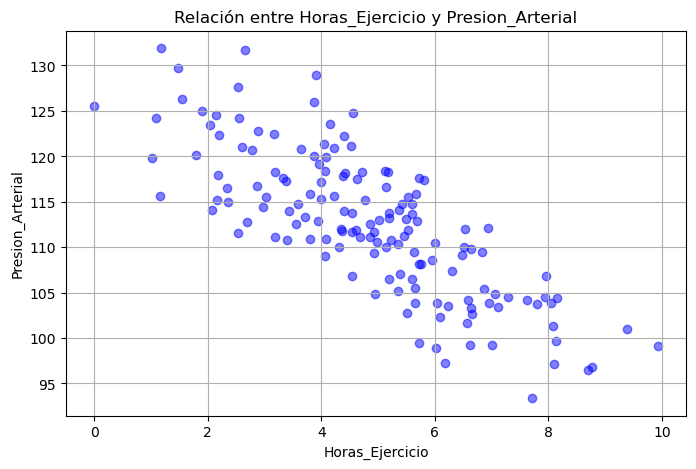

In [5]:
'''3. Visualización con Scatterplot
• Crear un gráfico de dispersión (scatterplot) para analizar la relación entre dos variables numéricas.
'''
plt.figure(figsize=(8,5))
plt.scatter(df['Horas_Ejercicio'], df['Presion_Arterial'], color='blue', alpha=0.5)
plt.xlabel('Horas_Ejercicio')
plt.ylabel('Presion_Arterial')
plt.title('Relación entre Horas_Ejercicio y Presion_Arterial')
plt.grid(True)
plt.show()

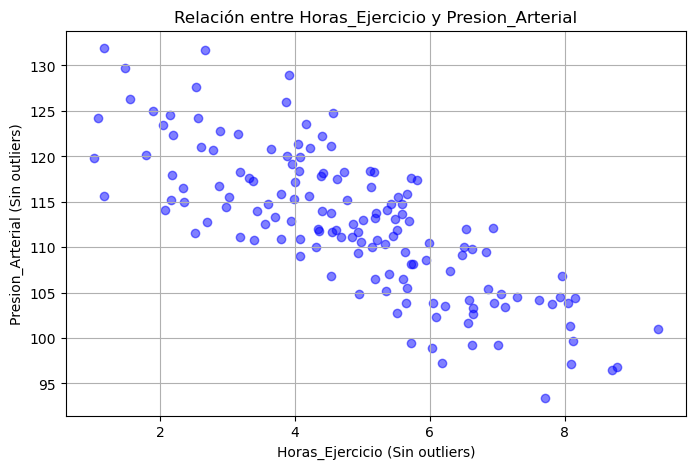

Coeficiente de correlación de Pearson (SciPy): -0.78
P-valor (SciPy): 0.0000000000
Interpretacion: existe una Correlación moderada negativa entre Horas ejercicio y presion arterial
la correlación es estadísticamente significativa


In [15]:
''''4. Cálculo del Coeficiente de Correlación de Pearson
• Calcular el coeficiente de correlación de Pearson e interpretar su resultado.'''

def filtrar_outliers(serie):
    Q1 = np.percentile(serie, 25)
    Q3 = np.percentile(serie, 75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    return serie[(serie >= limite_inferior) & (serie <= limite_superior)]

horas_filtradas = filtrar_outliers(df['Horas_Ejercicio'])
presion_filtradas = filtrar_outliers(df.loc[horas_filtradas.index, 'Presion_Arterial'])

plt.figure(figsize=(8,5))
plt.scatter(horas_filtradas, presion_filtradas, color='blue', alpha=0.5)
plt.xlabel('Horas_Ejercicio (Sin outliers)')
plt.ylabel('Presion_Arterial (Sin outliers)')
plt.title('Relación entre Horas_Ejercicio y Presion_Arterial')
plt.grid(True)
plt.show()

coef, p_value = stats.pearsonr(horas_filtradas, presion_filtradas)
print(f"Coeficiente de correlación de Pearson (SciPy): {coef:.2f}")
print(f"P-valor (SciPy): {p_value:.4f}")

if coef < 0:
    sentido = 'negativa'
else:
    sentido = 'positiva'
if abs(coef) >= 0.8:
    interpretacion = 'Correlación fuerte'
elif abs(coef) >= 0.5:
    interpretacion = 'Correlación moderada'
elif abs(coef) >= 0.2:
    interpretacion = 'Correlación débil'
else:
    interpretacion = 'Correlación despreciable o nula'
    
print(f'Interpretacion: existe una {interpretacion} {sentido} entre Horas ejercicio y presion arterial')

if p_value < 0.05:
    print('la correlación es estadísticamente significativa')
else:
    print('la correlación no es estadísticamente significativa')
                            


In [ ]:
'''5.Reflexión sobre Correlación vs. Causalidad
•
Explicar con ejemplos si la correlación encontrada implica causalidad o no.'''
# Aunque existe mayor horas de ejercicio, se muestra que tiende a disminuir la presion arterial.
# Correlación negativa.
# Las horas de ejercicio no necesariamente es la causa, a la disminución directa de la presión arterial, pueden existir otros factores
# Personas con dietas saludables, pueden tener dismunición de la presion arterial.
# Personas con altas horas de ejercicio presentan una dismunición en la presion arterial y pueden existir otros factores.

